# FoodMarket AI — J4 : analyse exploratoire et visualisations interactives

## 1. Préparation de l'environnement

In [1]:
import os

os.environ["OMP_NUM_THREADS"] = "4"
os.environ["NUMEXPR_NUM_THREADS"] = "4"


from pathlib import Path
import pandas as pd
import duckdb
import plotly.express as px


In [53]:
import requests
from datetime import datetime, timezone
import time

In [44]:
#Définir les chemins


racine = Path(r"D:\Projets_Data\FoodMarket_AI")

candidats_produits = [
    racine / "data/processed/dim_cereales_j3.parquet",
    racine / "data/processed/cereales_produits_j2.parquet",
    racine / "data/raw/cereales_off.parquet",
    racine / "data/raw/cereales_j1.csv"
]

candidats_prix = [
    racine / "data/processed/prices_j2.parquet",
    racine / "data/raw/prices_j2.parquet",
    racine / "data/raw/prices.parquet"
]

fichier_produits = next(
    (p for p in candidats_produits if p.exists()),
    None
)

fichier_prix = next(
    (p for p in candidats_prix if p.exists()),
    None
)

dossier_sortie = racine / "data/processed"
dossier_figures = racine / "reports/figures"

dossier_sortie.mkdir(parents=True, exist_ok=True)
dossier_figures.mkdir(parents=True, exist_ok=True)

print("Fichier produits :", fichier_produits)
print("Fichier prix :", fichier_prix)




Fichier produits : D:\Projets_Data\FoodMarket_AI\data\processed\dim_cereales_j3.parquet
Fichier prix : D:\Projets_Data\FoodMarket_AI\data\raw\prices.parquet


## 2. Nettoyage de données

In [45]:

if fichier_produits is None:
    raise FileNotFoundError(
        "Aucun fichier produit trouvé. "
        "Vérifie le référentiel des céréales du J2/J3."
    )

if fichier_produits.suffix == ".csv":
    df = pd.read_csv(
        fichier_produits,
        dtype={"code": "string"}
    )
else:
    df = pd.read_parquet(fichier_produits)

print("Nombre de lignes :", len(df))
print("Colonnes disponibles :")
print(df.columns.tolist())

display(df.head(5))


Nombre de lignes : 20
Colonnes disponibles :
['code', 'product_name', 'brands', 'quantity', 'nutrition_grades']


,code,product_name,brands,quantity,nutrition_grades
0,3168930010265,cruesly mélange de noix,"Cruesli, Quaker",None,None
1,3229820160672,Croustillant Chocolat,Bjorg,None,None
2,3229820019307,Flocons d'avoine,Bjorg,None,None
3,3229820129488,"muesli raisin,datte,figue",Bjorg,None,None
4,3387390123210,Chocapic,"Nestlé, Chocapic",None,None


In [46]:
#Vérifier la catégorie et les code-barres


if "code" not in df.columns:
    raise ValueError("La colonne code est absente.")

def est_cereale(tags):
    if isinstance(tags, np.ndarray):
        tags = tags.tolist()

    if isinstance(tags, (list, tuple)):
        return "en:breakfast-cereals" in tags

    if isinstance(tags, str):
        texte = tags.strip()

        if texte.startswith("["):
            try:
                tags_lus = ast.literal_eval(texte)
                return (
                    isinstance(tags_lus, list)
                    and "en:breakfast-cereals" in tags_lus
                )
            except (ValueError, SyntaxError):
                return False

        return "en:breakfast-cereals" in [
            t.strip() for t in texte.split(",")
        ]

    return False

if "categories_tags" in df.columns:
    df = df[
        df["categories_tags"].apply(est_cereale)
    ].copy()

elif fichier_produits.name == "dim_cereales_j3.parquet":
    print(
        "Référentiel du J3 utilisé : vérifier que "
        "sa catégorie a bien été validée au J3."
    )

else:
    raise ValueError(
        "Catégorie non vérifiable : le fichier "
        "ne possède pas categories_tags."
    )

df["code"] = (
    df["code"]
    .astype("string")
    .str.strip()
)

df = df[
    df["code"].str.fullmatch(r"\d{8,14}", na=False)
].copy()

print("Doublons de code :", df["code"].duplicated().sum())

df = df.drop_duplicates("code").copy()

if df.empty:
    raise ValueError("Aucune céréale vérifiée dans le fichier.")

print("Céréales conservées :", len(df))




Référentiel du J3 utilisé : vérifier que sa catégorie a bien été validée au J3.
Doublons de code : 0
Céréales conservées : 20


## 3. Récupérer et analyser les Nutri-Scores

- Préparer les colonnes nutritionnelles :

In [47]:

# Colonnes produits nécessaires
for colonne in ["product_name", "brands", "quantity"]:
    if colonne not in df.columns:
        df[colonne] = pd.NA

# Rechercher une colonne Nutri-Score existante
colonnes_possibles = [
    "nutriscore_grade",
    "nutrition_grades",
    "nutriscore",
    "nutrition_grade_fr"
]

colonne_trouvee = next(
    (c for c in colonnes_possibles if c in df.columns),
    None
)

if colonne_trouvee is not None:
    df["nutriscore_grade"] = (
        df[colonne_trouvee].astype("string")
    )
else:
    df["nutriscore_grade"] = pd.Series(
        pd.NA, index=df.index, dtype="string"
    )

df["nutriscore_grade"] = (
    df["nutriscore_grade"]
    .str.lower()
    .str.strip()
)

df["nutriscore_grade"] = (
    df["nutriscore_grade"]
    .where(
        df["nutriscore_grade"].isin(
            ["a", "b", "c", "d", "e"]
        )
    )
)

print("Nutri-Scores disponibles :",
      df["nutriscore_grade"].notna().sum())

print("Nutri-Scores manquants :",
      df["nutriscore_grade"].isna().sum())


Nutri-Scores disponibles : 0
Nutri-Scores manquants : 20


- Enrichissement ciblé par l'API Open Food Facts :

In [54]:

cache_path = (
    dossier_sortie / "nutriscores_cache_j4.csv"
)

if cache_path.exists():
    cache = pd.read_csv(
        cache_path,
        dtype={
            "code": "string",
            "nutriscore_grade": "string"
        }
    )
else:
    cache = pd.DataFrame(
        columns=[
            "code",
            "nutriscore_grade",
            "statut",
            "date_recuperation"
        ]
    )

# Réutiliser les résultats déjà récupérés
cache = cache.drop_duplicates("code", keep="last")

if not cache.empty:
    correspondance = (
        cache.set_index("code")["nutriscore_grade"]
    )

    df["nutriscore_grade"] = (
        df["nutriscore_grade"].fillna(
            df["code"].map(correspondance)
        )
    )

codes_deja_testes = set(cache["code"].dropna())

codes_a_tester = (
    df.loc[
        df["nutriscore_grade"].isna()
        & ~df["code"].isin(codes_deja_testes),
        "code"
    ]
    .head(20)
    .tolist()
)

headers = {
    "User-Agent": "FoodMarketAI/0.1 (educational project)"
}

for code in codes_a_tester:
    url = (
        "https://world.openfoodfacts.org/"
        f"api/v2/product/{code}.json"
    )

    try:
        reponse = requests.get(
            url,
            params={
                "fields": (
                    "code,nutriscore_grade,nutrition_grades"
                )
            },
            headers=headers,
            timeout=20
        )

        if reponse.status_code in (429, 503):
            print(
                "API limitée ou indisponible :",
                reponse.status_code
            )
            break

        reponse.raise_for_status()
        donnees = reponse.json()

        if donnees.get("status") == 1:
            produit = donnees.get("product", {})
            score = (
                produit.get("nutriscore_grade")
                or produit.get("nutrition_grades")
            )
            statut = "produit_trouve"
        else:
            score = None
            statut = "produit_introuvable"

        if score is not None:
            score = str(score).lower().strip()

        if score not in ["a", "b", "c", "d", "e"]:
            score = None

        nouvelle_ligne = pd.DataFrame([{
            "code": code,
            "nutriscore_grade": score,
            "statut": statut,
            "date_recuperation": datetime.now(
                timezone.utc
            ).isoformat()
        }])

        cache = pd.concat(
            [cache, nouvelle_ligne],
            ignore_index=True
        )

        cache.to_csv(cache_path, index=False)

        print(code, ":", score)
        time.sleep(5)

    except (requests.exceptions.RequestException, ValueError) as e:
        print("Erreur API :", e)
        break

# Actualiser le DataFrame
cache = cache.drop_duplicates("code", keep="last")

if not cache.empty:
    correspondance = (
        cache.set_index("code")["nutriscore_grade"]
    )

    df["nutriscore_grade"] = (
        df["nutriscore_grade"].fillna(
            df["code"].map(correspondance)
        )
    )

print(
    "Nutri-Scores désormais disponibles :",
    df["nutriscore_grade"].notna().sum()
)


3229820160672 : c
3229820019307 : a
3229820129488 : a
3387390123210 : b
5010477348678 : a
3229820782560 : a
7613036669146 : b
5010029000023 : a
5010477348357 : c
8410076610737 : d
3159470000120 : d
3229820769165 : b
3168930010906 : c
3168930009078 : a
20003166 : a
5010477348630 : c
3168930009795 : b
7613035449626 : b
5010477348395 : d
Nutri-Scores désormais disponibles : 20


In [55]:
#Calculer la répartition des Nutri-Scores


df["nutriscore_affiche"] = (
    df["nutriscore_grade"]
    .str.upper()
    .fillna("Non renseigné")
)

ordre = [
    "A", "B", "C", "D", "E", "Non renseigné"
]

repartition = (
    df["nutriscore_affiche"]
    .value_counts()
    .reindex(ordre, fill_value=0)
    .rename_axis("nutriscore")
    .reset_index(name="nb_produits")
)

total = len(df)

repartition["part_pct"] = (
    repartition["nb_produits"] / total * 100
).round(2)

display(repartition)

# Couverture nutritionnelle
notes_valides = df["nutriscore_grade"].notna()

couverture_nutri = notes_valides.mean() * 100

# Part A ou B parmi les notes renseignées
if notes_valides.sum() > 0:
    part_ab = (
        df.loc[notes_valides, "nutriscore_grade"]
        .isin(["a", "b"])
        .mean() * 100
    )
else:
    part_ab = None

print(
    f"Couverture Nutri-Score : {couverture_nutri:.2f} %"
)

print("Part A ou B parmi les notes valides :", part_ab)


,nutriscore,nb_produits,part_pct
0,A,7,35.0
1,B,6,30.0
2,C,4,20.0
3,D,3,15.0
4,E,0,0.0
5,Non renseigné,0,0.0


Couverture Nutri-Score : 100.00 %
Part A ou B parmi les notes valides : 65.0


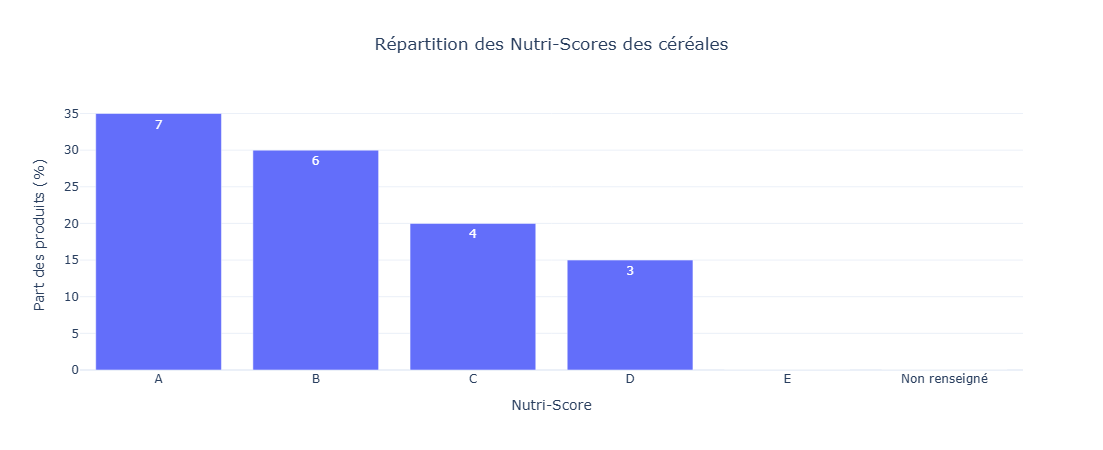

In [56]:
#Graphique interactif Nutri-Score


fig_nutri = px.bar(
    repartition,
    x="nutriscore",
    y="part_pct",
    text="nb_produits",
    category_orders={"nutriscore": ordre},
    title="Répartition des Nutri-Scores des céréales",
    labels={
        "nutriscore": "Nutri-Score",
        "part_pct": "Part des produits (%)"
    },
    hover_data=["nb_produits"],
    template="plotly_white"
)

fig_nutri.update_layout(
    height=450,
    title_x=0.5
)

fig_nutri.show()


## 4. Analyse des marques de céréales

,marque,nb_produits
0,Bjorg,5
1,"Nestlé, Chocapic",3
2,The Jordans & Ryvita Company Limited - A Divis...,2
3,Jordans,2
4,"Cruesli, Quaker",1
5,Weetabix,1
6,Nature Valley,1
7,KELLOGG S PRODUITS ALIMENT SAS,1
8,PEPSICO FRANCE,1
9,Quaker,1


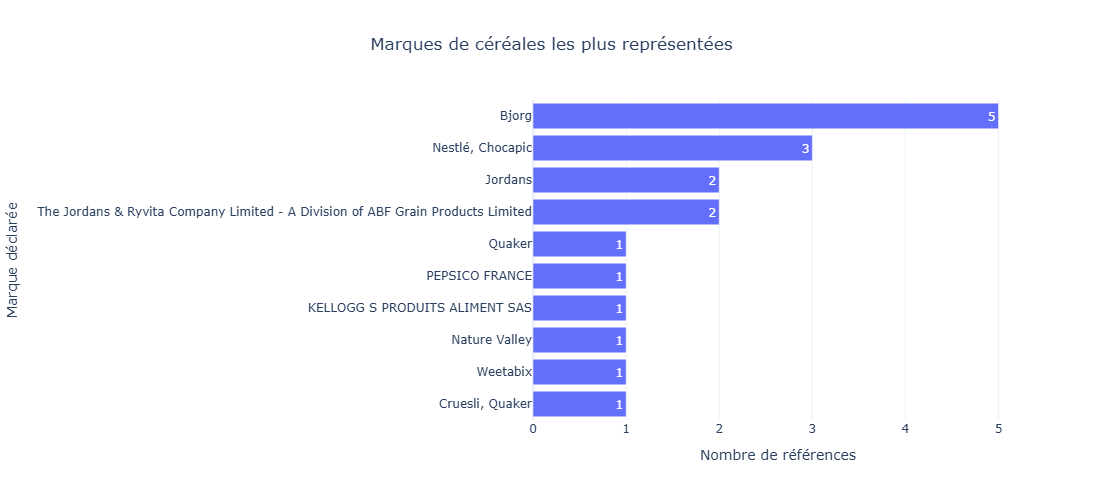

In [57]:

df["marque"] = (
    df["brands"]
    .astype("string")
    .fillna("Non renseignée")
    .str.strip()
    .replace("", "Non renseignée")
)

top_marques = (
    df["marque"]
    .value_counts()
    .head(10)
    .rename_axis("marque")
    .reset_index(name="nb_produits")
)

display(top_marques)

fig_marques = px.bar(
    top_marques.sort_values("nb_produits"),
    x="nb_produits",
    y="marque",
    orientation="h",
    text="nb_produits",
    title="Marques de céréales les plus représentées",
    labels={
        "nb_produits": "Nombre de références",
        "marque": "Marque déclarée"
    },
    template="plotly_white"
)

fig_marques.update_layout(
    height=500,
    title_x=0.5
)

fig_marques.show()


## 5. Réalisation de la jointure SQL avec Open Prices

In [61]:
#Lire le schéma des prix avec DuckDB


con = None
prix_disponibles = fichier_prix is not None
fig_prix = None

if prix_disponibles:

    con = duckdb.connect()

    con.execute("SET memory_limit = '4GB'")
    con.execute("SET threads = 2")

    con.read_parquet(
        str(fichier_prix)
    ).create_view("prix_bruts")

    schema_prix = con.execute("""
        DESCRIBE prix_bruts
    """).df()

    display(schema_prix)

    nb_lignes = con.execute("""
        SELECT COUNT(*) FROM prix_bruts
    """).fetchone()[0]

    print("Observations de prix brutes :", nb_lignes)

else:
    print(
        "Fichier prix absent. "
        "Les analyses nutritionnelles restent possibles."
    )


,column_name,column_type,null,key,default,extra
0,id,BIGINT,YES,None,None,None
1,type,VARCHAR,YES,None,None,None
2,product_code,VARCHAR,YES,None,None,None
3,product_name,VARCHAR,YES,None,None,None
4,category_tag,VARCHAR,YES,None,None,None
5,labels_tags,VARCHAR[],YES,None,None,None
6,origins_tags,VARCHAR[],YES,None,None,None
7,price,"DECIMAL(10,3)",YES,None,None,None
8,price_is_discounted,BOOLEAN,YES,None,None,None
9,price_without_discount,"DECIMAL(10,3)",YES,None,None,None


Observations de prix brutes : 339261


In [64]:
#Créer la jointure des céréales et des prix


if prix_disponibles:

    colonnes_prix = set(
        schema_prix["column_name"].tolist()
    )

    obligatoires = {
        "product_code",
        "price",
        "date"
    }

    manquantes = obligatoires - colonnes_prix

    if manquantes:
        raise ValueError(
            f"Colonnes absentes : {manquantes}"
        )

    con.complete()

    # Dimension des céréales
    df_dimension = df[
        [
            "code",
            "product_name",
            "brands",
            "quantity",
            "nutriscore_grade"
        ]
    ].copy()

    con.register("cereales_j4", df_dimension)

    # Gérer les colonnes facultatives
    def champ_prix(nom, type_sql):
        if nom in colonnes_prix:
            return f"TRY_CAST(p.{nom} AS {type_sql})"
        return f"CAST(NULL AS {type_sql})"

    requete = f"""
        SELECT
            {champ_prix("id", "VARCHAR")}
                AS id_observation,

            c.code,
            c.product_name AS nom_produit,
            c.brands AS marque,
            c.quantity AS quantite,
            c.nutriscore_grade,

            TRY_CAST(p.price AS DOUBLE) AS prix,
            TRY_CAST(p.date AS DATE) AS date_prix,

            {champ_prix("currency", "VARCHAR")}
                AS devise,

            {champ_prix("price_per", "VARCHAR")}
                AS unite_prix,

            {champ_prix("location_id", "VARCHAR")}
                AS location_id,

            {champ_prix("price_is_discounted", "BOOLEAN")}
                AS est_promotion

        FROM prix_bruts AS p

        INNER JOIN cereales_j4 AS c
            ON TRIM(
                CAST(p.product_code AS VARCHAR)
            ) = c.code
    """

    con.execute(
        "CREATE OR REPLACE VIEW prix_cereales AS "
        + requete
    )

    resultat_jointure = con.execute("""
        SELECT
            COUNT(*) AS nb_observations,
            COUNT(DISTINCT code) AS nb_cereales_avec_prix
        FROM prix_cereales
    """).df()

    display(resultat_jointure)

else:
    print("Jointure non exécutée : prix indisponibles.")


,nb_observations,nb_cereales_avec_prix
0,385,20


In [65]:
#Controler la qualité


if prix_disponibles:

    qualite_prix = con.execute("""
        SELECT
            COUNT(*) AS nb_lignes,

            COUNT(DISTINCT code) AS nb_produits,

            COUNT(*) FILTER (
                WHERE prix IS NULL OR prix <= 0
            ) AS prix_invalides,

            COUNT(*) FILTER (
                WHERE date_prix IS NULL
            ) AS dates_invalides,

            COUNT(*) FILTER (
                WHERE devise IS NULL
            ) AS devises_manquantes,

            COUNT(*) FILTER (
                WHERE unite_prix IS NULL
            ) AS unites_manquantes

        FROM prix_cereales
    """).df()

    display(qualite_prix)

    nb_avec_prix = int(
        qualite_prix.loc[0, "nb_produits"]
    )

    couverture_prix = (
        nb_avec_prix / len(df) * 100
    )

    print(
        f"Couverture tarifaire : {couverture_prix:.2f} %"
    )

else:
    print("Contrôles tarifaires non disponibles.")


,nb_lignes,nb_produits,prix_invalides,dates_invalides,devises_manquantes,unites_manquantes
0,385,20,0,0,0,385


Couverture tarifaire : 100.00 %


## 6. Préparer les statistiques tarifaires

In [66]:
#Examiner les unités


if prix_disponibles:

    unites_prix = con.execute("""
        SELECT
            devise,
            unite_prix,
            COUNT(*) AS nb_observations

        FROM prix_cereales

        GROUP BY devise, unite_prix

        ORDER BY nb_observations DESC
    """).df()

    display(unites_prix)


,devise,unite_prix,nb_observations
0,EUR,None,384
1,ADP,None,1


In [68]:
#Statistiques par céréale


stats_prix = pd.DataFrame()
nb_prix_comparables = 0

if prix_disponibles:

    con.execute("""
        CREATE OR REPLACE VIEW prix_eur_unit AS

        SELECT *
        FROM prix_cereales

        WHERE UPPER(TRIM(devise)) = 'EUR'
          AND prix > 0
          AND date_prix IS NOT NULL
    """)

    nb_prix_comparables = con.execute("""
        SELECT COUNT(*)
        FROM prix_eur_unit
    """).fetchone()[0]

    print(
        "Observations EUR à l'unité :",
        nb_prix_comparables
    )

    stats_prix = con.execute("""
        SELECT
            code,
            MAX(nom_produit) AS nom_produit,
            COUNT(*) AS nb_releves,
            ROUND(MIN(prix), 2) AS prix_min,
            ROUND(MEDIAN(prix), 2) AS prix_median,
            ROUND(MAX(prix), 2) AS prix_max

        FROM prix_eur_unit

        GROUP BY code
        ORDER BY nb_releves DESC
        LIMIT 20
    """).df()

    display(stats_prix)


Observations EUR à l'unité : 384


,code,nom_produit,nb_releves,prix_min,prix_median,prix_max
0,5010477348678,Special Muesli 30% fruits & noix,74,3.14,4.19,4.85
1,8410076610737,Barre de céréales protéinés,33,2.47,3.17,5.04
2,5010477348357,Country Crisp 4 noix,26,2.93,3.62,4.79
3,3168930010265,cruesly mélange de noix,26,2.79,3.95,4.25
4,3229820160672,Croustillant Chocolat,25,3.25,3.59,5.70
5,3229820129488,"muesli raisin,datte,figue",21,1.84,2.40,4.05
6,5010029000023,Original,20,2.97,3.83,4.25
7,3229820769165,Muesli avoine chocolat bio,20,2.01,3.78,5.25
8,3168930010906,Cruesli Chocolat noir,19,2.49,2.99,4.64
9,5010477348395,Country Crisp - Chocolat noir 70% cacao,18,3.49,4.31,4.90


In [74]:
#Statistiques Prix global de tous les produits
global_stats_prix = con.execute("""
        SELECT
            COUNT(*) AS nb_releves,
            ROUND(MIN(prix), 2) AS prix_min,
            ROUND(MEDIAN(prix), 2) AS prix_median,
            ROUND(MAX(prix), 2) AS prix_max

        FROM prix_eur_unit
        """).df()

display(global_stats_prix)

,nb_releves,prix_min,prix_median,prix_max
0,384,0.69,3.7,6.5


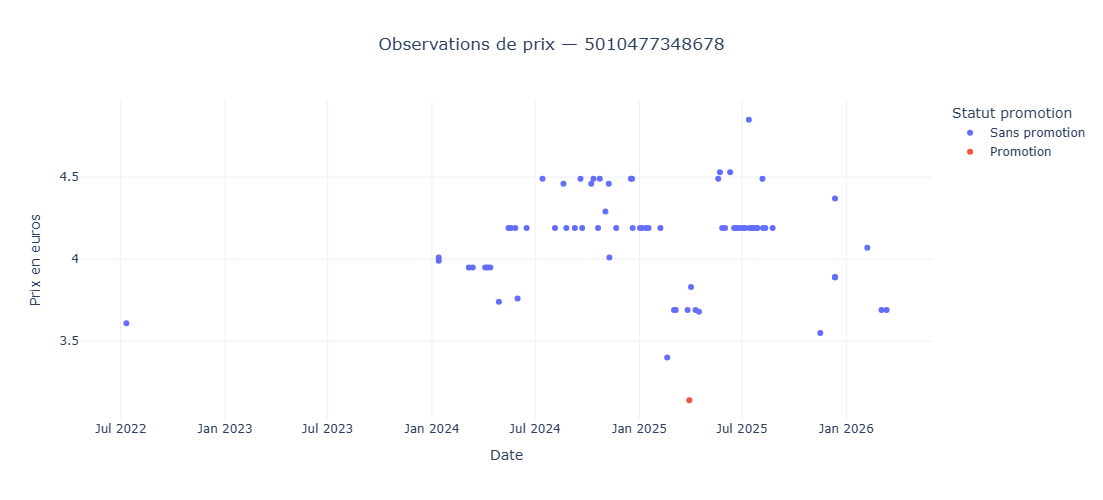

In [69]:
#Visualiser les prix d'une céréale


if not stats_prix.empty:

    code_choisi = stats_prix.loc[0, "code"]

    df_evolution = con.execute("""
        SELECT
            date_prix,
            prix,
            COALESCE(
                location_id,
                'Non renseigné'
            ) AS magasin,

            CASE
                WHEN est_promotion = TRUE
                    THEN 'Promotion'
                WHEN est_promotion = FALSE
                    THEN 'Sans promotion'
                ELSE 'Non renseigné'
            END AS promotion

        FROM prix_eur_unit

        WHERE code = ?

        ORDER BY date_prix
        LIMIT 1000
    """, [code_choisi]).df()

    fig_prix = px.scatter(
        df_evolution,
        x="date_prix",
        y="prix",
        color="promotion",
        hover_data=["magasin"],
        title=f"Observations de prix — {code_choisi}",
        labels={
            "date_prix": "Date",
            "prix": "Prix en euros",
            "promotion": "Statut promotion"
        },
        template="plotly_white"
    )

    fig_prix.update_layout(
        height=500,
        title_x=0.5
    )

    fig_prix.show()

else:
    print(
        "Aucune observation de prix comparable "
        "pour cette visualisation."
    )


## 7. Enregistrer les résultats du J4

In [70]:
#Sauvegarder les données enrichies


# Référentiel des céréales avec Nutri-Score
fichier_nutrition = (
    dossier_sortie / "dim_cereales_nutrition_j4.parquet"
)

colonnes_export = [
    "code",
    "product_name",
    "brands",
    "quantity",
    "nutriscore_grade"
]

df[colonnes_export].to_parquet(
    fichier_nutrition,
    index=False
)

print("Produits enregistrés :", fichier_nutrition)

# Sauvegarder les prix issus de la jointure
if prix_disponibles:

    fichier_jointure = (
        dossier_sortie / "fact_prix_cereales_j4.parquet"
    )

    con.sql("""
        SELECT *
        FROM prix_cereales
        WHERE prix > 0
          AND date_prix IS NOT NULL
    """).to_parquet(str(fichier_jointure))

    print("Prix enregistrés :", fichier_jointure)


Produits enregistrés : D:\Projets_Data\FoodMarket_AI\data\processed\dim_cereales_nutrition_j4.parquet
Prix enregistrés : D:\Projets_Data\FoodMarket_AI\data\processed\fact_prix_cereales_j4.parquet


In [71]:
#Exporter les graphiques Plotly


fig_nutri.write_html(
    str(dossier_figures / "j4_nutriscores.html"),
    include_plotlyjs="cdn"
)

fig_marques.write_html(
    str(dossier_figures / "j4_marques.html"),
    include_plotlyjs="cdn"
)

if fig_prix is not None:
    fig_prix.write_html(
        str(dossier_figures / "j4_prix_cereales.html"),
        include_plotlyjs="cdn"
    )

print("Graphiques HTML enregistrés.")


Graphiques HTML enregistrés.
